# Matplot Library 
Examples of plots using matplot

In [2]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [11]:
# --- Reading the dataset ---
df_genres = pd.read_csv('C:\\Users\\oiko\\Desktop\\DIT\\Data_Mining\\Multimodal_Music_Analysis\\data\\id_genres.csv', delimiter='\t')
df_information = pd.read_csv('C:\\Users\\oiko\\Desktop\\DIT\\Data_Mining\\Multimodal_Music_Analysis\\data\\id_information.csv', delimiter='\t')

# --- Cleaning the dataset ---
top_genres = df_genres['genres'].value_counts().head(5).index.to_list()
filtered_genres_df = df_genres[df_genres['genres'].isin(top_genres)]


# ---- Merging the datasets ---
df = pd.merge(filtered_genres_df, df_information, on='id').reindex()
df.head()

,id,genres,artist,song,album_name
0,0009fFIM1eYThaPg,pop,Cheryl,Rain on Me,3 Words
1,00P2bHdWFkghmDqz,soul,Michael Kiwanuka,Tell Me a Tale,Home Again
2,00XWljDxNBgBKEEA,pop,José Luis Perales,Y cómo es él?,Celebridades- Jose Luis Perales
3,00b6fV3nx5z2b8Ls,pop,Glee Cast,ABC,"Glee: The Music, Volume 7"
4,013QDoTqbexEwkHr,pop,George Michael,Patience,Patience


### MATPLOT STRUCTURE

#### BAR PLOT

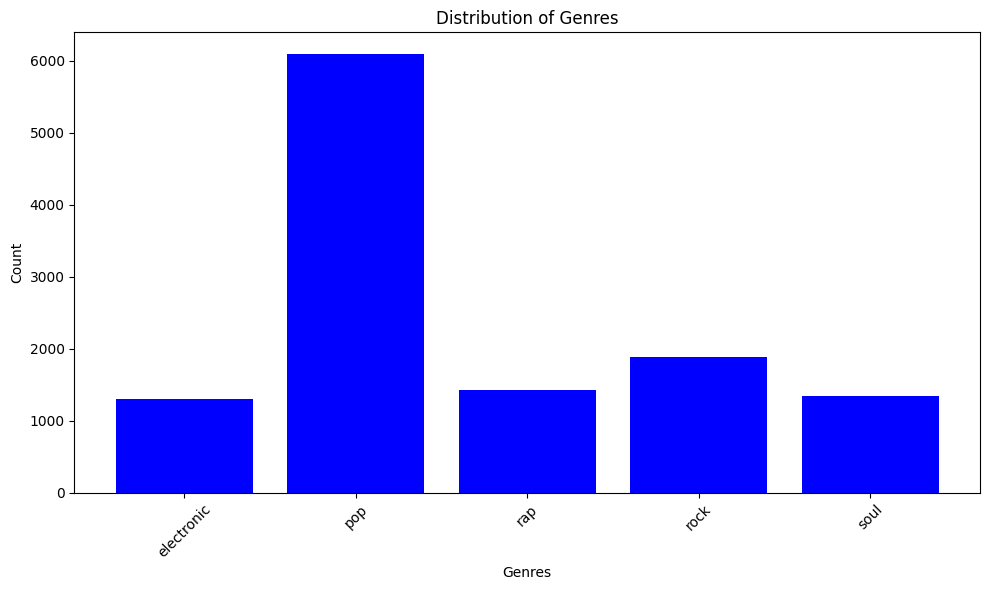

In [22]:
genres_sum = df.groupby('genres').size().to_dict()

genres = list(genres_sum.keys())
counts = list(genres_sum.values())

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(genres, counts, color='blue')
ax.set_xlabel('Genres')
ax.set_ylabel('Count')
ax.set_title('Distribution of Genres')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### SCATTER PLOT

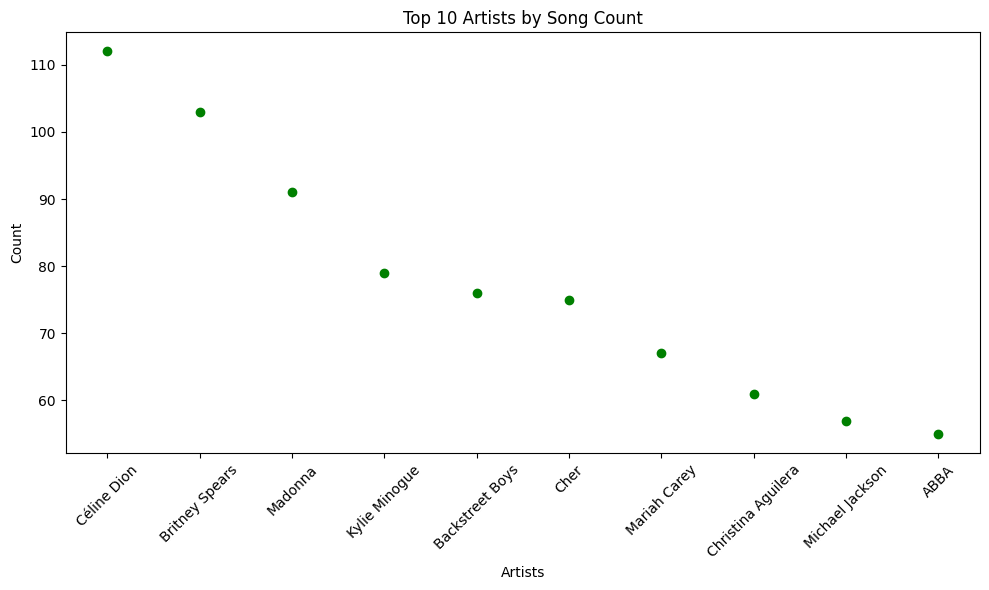

In [31]:
artist_counts = df.groupby('artist').size().sort_values(ascending=False).head(10)

artists = artist_counts.index.tolist()
counts = artist_counts.values.tolist()


fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(artists, counts, color='green')
ax.set_xlabel('Artists')
ax.set_ylabel('Count')
ax.set_title('Top 10 Artists by Song Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


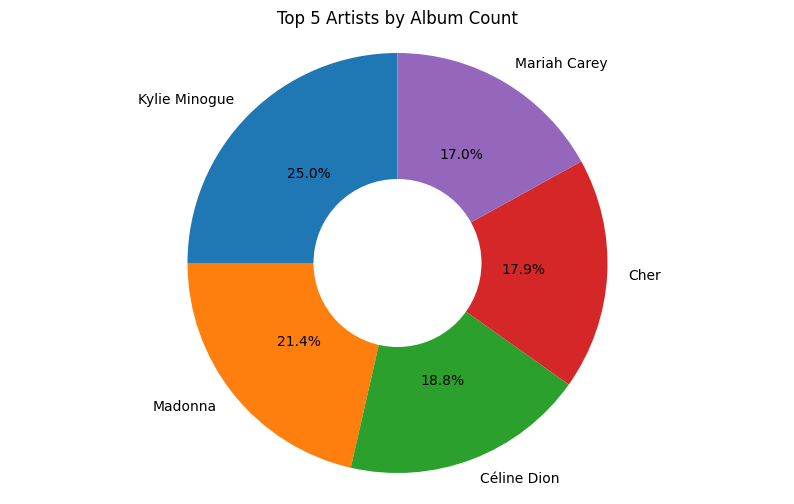

In [42]:
columns = ['artist', 'album_name']
df_albums = df[columns].drop_duplicates()
album_counts = df_albums.groupby('artist').size().sort_values(ascending=False).head(5)
artists = album_counts.index.tolist()
counts = album_counts.values.tolist()

fig, ax = plt.subplots(figsize=(10, 6))
ax.pie(counts, labels=artists, autopct='%1.1f%%', startangle=90)
ax.set_title('Top 5 Artists by Album Count')
plt.axis('equal')
# --- making a donut chart ---
center_circle = plt.Circle((0, 0), 0.40, fc='white')
fig.gca().add_artist(center_circle)
plt.show()
